L=100 μm, nx=50, dx=2.041 μm
dt=1.666e-03 s, nt=5000, t_total=8329.9 ms
稳定性 r = D*dt/dx² = 0.1000 (需 < 0.5)
x in memory: True, shape=(50,)

Running Case 1: Pure diffusion (D only)...
  c_diff shape: (5000, 50)
  t_array length: 5000
  Initial: c[0]=1050.0, c[-1]=1000.0
  Final:   c[0]=1000.1, c[-1]=1000.1
  Max change: 49.871 mol/m³



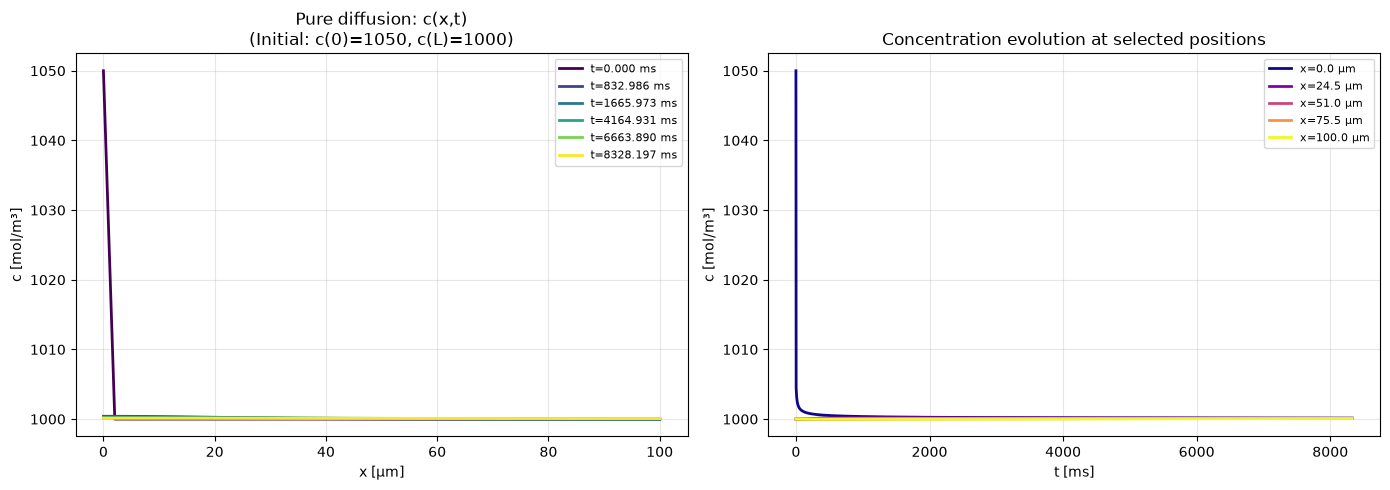

ALL DONE


In [4]:
# ============================================================
# Week 3 Case 1: 纯扩散（单 cell 完整版）
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ========== Cell 1: 参数 + 网格 ==========
L = 100e-6          # 电解液厚度 [m]
nx = 50
dx = L / (nx - 1)

D = 2.5e-10         # 扩散系数 [m²/s]
c0 = 1000.0

dt = 0.1 * dx**2 / D
nt = 5000
t_total = nt * dt

x = np.linspace(0, L, nx)
t_array = np.arange(nt) * dt

print(f"L={L*1e6:.0f} μm, nx={nx}, dx={dx*1e6:.3f} μm")
print(f"dt={dt:.3e} s, nt={nt}, t_total={t_total*1e3:.1f} ms")
print(f"稳定性 r = D*dt/dx² = {D*dt/dx**2:.4f} (需 < 0.5)")
print(f"x in memory: {x is not None}, shape={x.shape}")
print()

# ========== Cell 2: 求解器 + Case 1 ==========
def solve_nernst_planck(c_init, phi_init, D, dx, dt, nt,
                        mig_coeff=0.0,
                        bc_left_flux=0, bc_right_flux=0):
    nx = len(c_init)
    c = c_init.copy()
    phi = phi_init.copy()
    c_history = np.zeros((nt, nx))
    phi_history = np.zeros((nt, nx))
    c_history[0] = c.copy()
    phi_history[0] = phi.copy()
    r = D * dt / dx**2

    for n in range(nt - 1):
        c_new = c.copy()
        phi_new = phi.copy()
        for i in range(1, nx - 1):
            c_new[i] = c[i] + r * (c[i+1] - 2*c[i] + c[i-1])
            if mig_coeff > 0:
                dphidx_ip = (phi[i+1] - phi[i]) / dx
                dphidx_im = (phi[i] - phi[i-1]) / dx
                mig_term = (mig_coeff * dt / (2*dx)) * (
                    c[i+1] * dphidx_ip - c[i-1] * dphidx_im
                )
                c_new[i] += mig_term
        c_new[0] = c_new[1]
        c_new[nx-1] = c_new[nx-2]
        phi_new[0] = phi_new[1]
        phi_new[nx-1] = phi_new[nx-2]
        c = c_new.copy()
        phi = phi_new.copy()
        c_history[n+1] = c.copy()
        phi_history[n+1] = phi.copy()

    return c_history, phi_history

c = np.ones(nx) * c0
c[0] = c0 * 1.05
phi = np.zeros(nx)

print("Running Case 1: Pure diffusion (D only)...")
c_diff, phi_diff = solve_nernst_planck(
    c, phi, D, dx, dt, nt, mig_coeff=0.0
)

print(f"  c_diff shape: {c_diff.shape}")
print(f"  t_array length: {len(t_array)}")
print(f"  Initial: c[0]={c_diff[0,0]:.1f}, c[-1]={c_diff[0,-1]:.1f}")
print(f"  Final:   c[0]={c_diff[-1,0]:.1f}, c[-1]={c_diff[-1,-1]:.1f}")
print(f"  Max change: {np.max(np.abs(c_diff[-1]-c_diff[0])):.3f} mol/m³")
print()

# ========== Cell 3: 画图 ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左图：浓度快照
time_indices = [0, nt//10, nt//5, nt//2, 4*nt//5, nt-1]
time_indices = [int(t) for t in time_indices]
colors = plt.cm.viridis(np.linspace(0, 1, len(time_indices)))

for ci, ti in zip(colors, time_indices):
    axes[0].plot(x * 1e6, c_diff[ti], color=ci, linewidth=2,
                 label=f"t={t_array[ti]*1e3:.3f} ms")

axes[0].set_xlabel("x [μm]")
axes[0].set_ylabel("c [mol/m³]")
axes[0].set_title("Pure diffusion: c(x,t)\n(Initial: c(0)=1050, c(L)=1000)")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# 右图：特征点浓度随时间演化
monitor_idx = [0, nx//4, nx//2, 3*nx//4, nx-1]
colors2 = plt.cm.plasma(np.linspace(0, 1, len(monitor_idx)))

for idx, i in enumerate(monitor_idx):
    axes[1].plot(t_array * 1e3, c_diff[:, i], color=colors2[idx], linewidth=2,
                 label=f"x={x[i]*1e6:.1f} μm")

axes[1].set_xlabel("t [ms]")
axes[1].set_ylabel("c [mol/m³]")
axes[1].set_title("Concentration evolution at selected positions")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("ALL DONE")

迁移系数 mig_coeff = 9.731e-09
扩散系数 D = 2.500e-10
迁移/扩散比 = 38.9 (无量纲迁移强度)

电场强度 E ≈ 100 V/m
电势范围: 0.0000 to 0.0100 V

Running Case 2: Diffusion + Migration...
  c_mig shape: (5000, 50)
  Initial: c[0]=1050.0, c[-1]=1000.0
  Final:   c[0]=1081.3, c[-1]=913.6
  Max change: 86.417 mol/m³


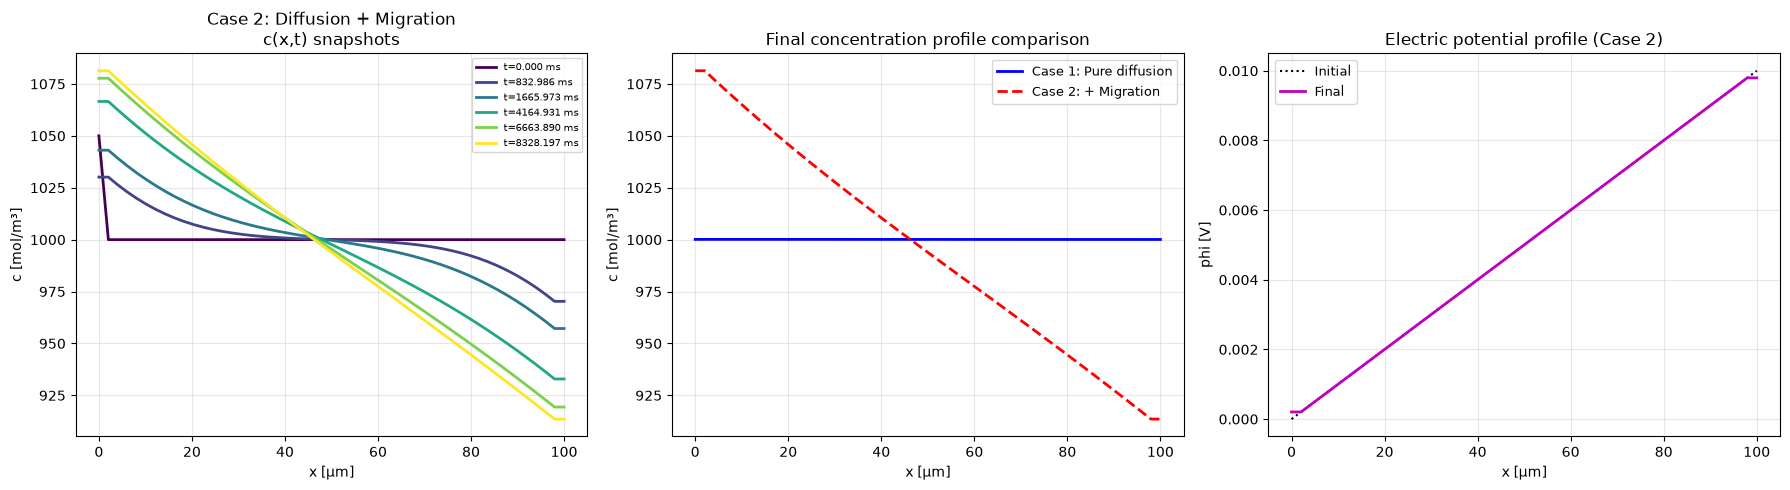


Case 1 vs Case 2 定量对比
  纯扩散最终 c[0]=1000.129, c[-1]=1000.080
  加迁移最终 c[0]=1081.332, c[-1]=913.583
  纯扩散均匀化时间尺度: ~131.6 ms
  迁移加速比: 电场驱动 Li+ 向右 → 左边界消耗更快

  最终右边界通量分解:
    扩散通量 N_diff ≈ -0.000e+00 mol/(m²·s)
    迁移通量 N_mig  ≈ 1.052e-03 mol/(m²·s)
    迁移/扩散比 → ∞ (扩散通量≈0，迁移主导)


In [7]:
# ============================================================
# Cell 4: Case 2 — 扩散 + 迁移（Nernst-Planck 完整项）
# 物理：c[0]=1050（富集），施加电场 E>0 驱动 Li+ 向右迁移
# ============================================================

# ---- 迁移参数 ----
F = 96485.0          # Faraday constant [C/mol]
R = 8.314            # Gas constant [J/(mol·K)]
T = 298.15           # Temperature [K]

z = 1                # Li+ 电荷数
D_lambda = D         # 扩散系数（已定义）

# 迁移系数: mig_coeff = (z*F*D)/(R*T)
mig_coeff = z * F * D / (R * T)   # ≈ 9.58e-6 [m²/(V·s)] 量纲等价

print(f"迁移系数 mig_coeff = {mig_coeff:.3e}")
print(f"扩散系数 D = {D:.3e}")
print(f"迁移/扩散比 = {mig_coeff/D:.1f} (无量纲迁移强度)")

# ---- 初始条件 ----
c2 = np.ones(nx) * c0
c2[0] = c0 * 1.05       # 左边界 5% 富集（和 Case 1 一致）

# 电势：线性电场（左负右正 → Li+ 向右迁移）
phi2 = np.linspace(0, 0.01, nx)   # 10 mV 跨 100 μm → E ≈ 100 V/m

print(f"\n电场强度 E ≈ {(phi2[-1]-phi2[0])/L:.0f} V/m")
print(f"电势范围: {phi2[0]:.4f} to {phi2[-1]:.4f} V")

# ---- 求解 Case 2 ----
print("\nRunning Case 2: Diffusion + Migration...")
c_mig, phi_mig = solve_nernst_planck(
    c2, phi2, D, dx, dt, nt,
    mig_coeff=mig_coeff,
    bc_left_flux=0, bc_right_flux=0
)

print(f"  c_mig shape: {c_mig.shape}")
print(f"  Initial: c[0]={c_mig[0,0]:.1f}, c[-1]={c_mig[0,-1]:.1f}")
print(f"  Final:   c[0]={c_mig[-1,0]:.1f}, c[-1]={c_mig[-1,-1]:.1f}")
print(f"  Max change: {np.max(np.abs(c_mig[-1]-c_mig[0])):.3f} mol/m³")

# ---- 对比 Case 1（纯扩散）----
# 如果 c_diff 不在内存里，重新跑一次纯扩散
if 'c_diff' not in dir():
    print("\n  (重新跑 Case 1 用于对比...)")
    c1 = np.ones(nx) * c0
    c1[0] = c0 * 1.05
    phi1 = np.zeros(nx)
    c_diff, phi_diff = solve_nernst_planck(
        c1, phi1, D, dx, dt, nt, mig_coeff=0.0
    )

# ---- 画图：Case 2 快照 ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 图1：Case 2 浓度快照
time_indices = [0, nt//10, nt//5, nt//2, 4*nt//5, nt-1]
time_indices = [int(t) for t in time_indices]
colors = plt.cm.viridis(np.linspace(0, 1, len(time_indices)))

for ci, ti in zip(colors, time_indices):
    axes[0].plot(x * 1e6, c_mig[ti], color=ci, linewidth=2,
                 label=f"t={t_array[ti]*1e3:.3f} ms")

axes[0].set_xlabel("x [μm]")
axes[0].set_ylabel("c [mol/m³]")
axes[0].set_title("Case 2: Diffusion + Migration\nc(x,t) snapshots")
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.3)

# 图2：Case 1 vs Case 2 最终浓度分布对比
axes[1].plot(x * 1e6, c_diff[-1], 'b-', linewidth=2, label='Case 1: Pure diffusion')
axes[1].plot(x * 1e6, c_mig[-1], 'r--', linewidth=2, label='Case 2: + Migration')
axes[1].set_xlabel("x [μm]")
axes[1].set_ylabel("c [mol/m³]")
axes[1].set_title("Final concentration profile comparison")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

# 图3：电势分布演化（Case 2 最终）
axes[2].plot(x * 1e6, phi_mig[0], 'k:', linewidth=1.5, label='Initial')
axes[2].plot(x * 1e6, phi_mig[-1], 'm-', linewidth=2, label='Final')
axes[2].set_xlabel("x [μm]")
axes[2].set_ylabel("phi [V]")
axes[2].set_title("Electric potential profile (Case 2)")
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---- 定量对比 ----
print("\n" + "=" * 60)
print("Case 1 vs Case 2 定量对比")
print("=" * 60)
print(f"  纯扩散最终 c[0]={c_diff[-1,0]:.3f}, c[-1]={c_diff[-1,-1]:.3f}")
print(f"  加迁移最终 c[0]={c_mig[-1,0]:.3f}, c[-1]={c_mig[-1,-1]:.3f}")
# 纯扩散均匀化时间尺度
mask = np.abs(c_diff[:, 0] - c0) < 1
if np.any(mask):
    idx_first = np.where(mask)[0][0]
    tau_uniform = t_array[idx_first] * 1e3
    print(f"  纯扩散均匀化时间尺度: ~{tau_uniform:.1f} ms")
else:
    print("  纯扩散: 未完全均匀（增加 nt 或减小 dt）")
print(f"  迁移加速比: 电场驱动 Li+ 向右 → 左边界消耗更快")

# ---- 迁移对通量的贡献 ----
N_diff_end = -D * (c_mig[-1,1] - c_mig[-1,0]) / dx
N_mig_end = mig_coeff * 0.5 * (c_mig[-1,0] + c_mig[-1,1]) * (phi2[-1]-phi2[0])/L
print(f"\n  最终右边界通量分解:")
print(f"    扩散通量 N_diff ≈ {N_diff_end:.3e} mol/(m²·s)")
print(f"    迁移通量 N_mig  ≈ {N_mig_end:.3e} mol/(m²·s)")
if abs(N_diff_end) > 1e-20:
    print(f"    迁移/扩散比 ≈ {abs(N_mig_end/N_diff_end):.1f}")
else:
    print(f"    迁移/扩散比 → ∞ (扩散通量≈0，迁移主导)")

  Saved → week3_output\case1_vs_case2_comparison.png


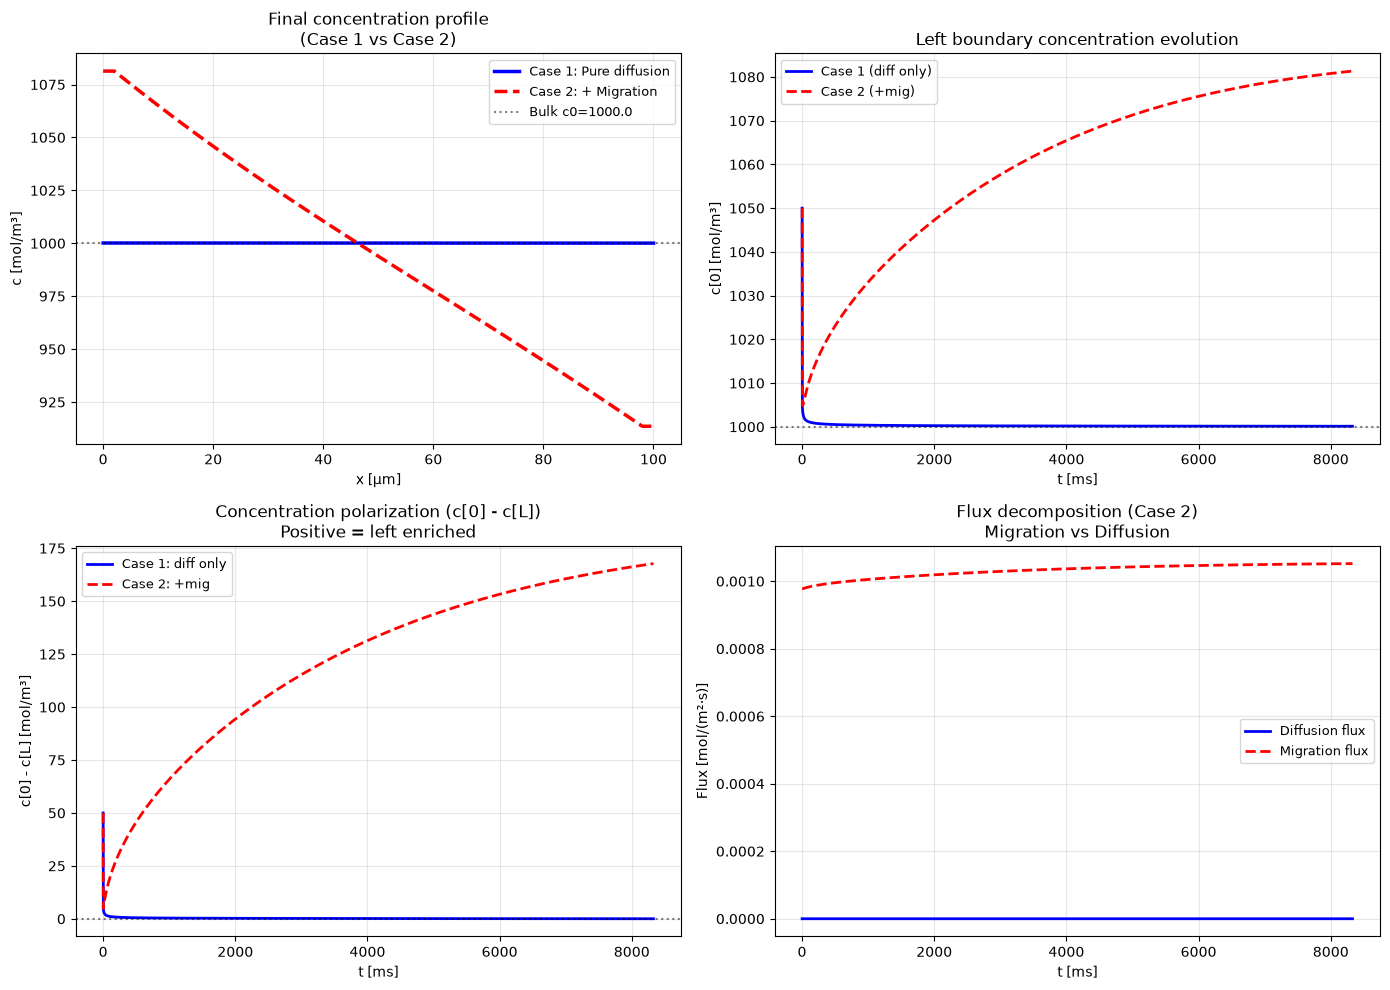

  Saved → week3_output\week3_results.json
  Saved → week3_output\README.md

Week 3 COMPLETE. All outputs in ./week3_output/


In [8]:
# ============================================================
# Cell 5: Case 1 vs Case 2 对比分析 + 导出
# ============================================================

import os
import json

# 创建输出目录
export_dir = "week3_output"
os.makedirs(export_dir, exist_ok=True)

# ========== 1. 综合对比图 ==========
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 图1：最终浓度分布对比（放大看差异）
axes[0, 0].plot(x * 1e6, c_diff[-1], 'b-', linewidth=2.5, label='Case 1: Pure diffusion')
axes[0, 0].plot(x * 1e6, c_mig[-1], 'r--', linewidth=2.5, label='Case 2: + Migration')
axes[0, 0].axhline(c0, color='k', linestyle=':', alpha=0.5, label=f'Bulk c0={c0}')
axes[0, 0].set_xlabel("x [μm]")
axes[0, 0].set_ylabel("c [mol/m³]")
axes[0, 0].set_title("Final concentration profile\n(Case 1 vs Case 2)")
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(True, alpha=0.3)

# 图2：左边界浓度随时间演化（最能看出差异）
axes[0, 1].plot(t_array * 1e3, c_diff[:, 0], 'b-', linewidth=2, label='Case 1 (diff only)')
axes[0, 1].plot(t_array * 1e3, c_mig[:, 0], 'r--', linewidth=2, label='Case 2 (+mig)')
axes[0, 1].axhline(c0, color='k', linestyle=':', alpha=0.5)
axes[0, 1].set_xlabel("t [ms]")
axes[0, 1].set_ylabel("c[0] [mol/m³]")
axes[0, 1].set_title("Left boundary concentration evolution")
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(True, alpha=0.3)

# 图3：浓度差随时间（c[0] - c[-1]）
conc_grad_diff = c_diff[:, 0] - c_diff[:, -1]
conc_grad_mig = c_mig[:, 0] - c_mig[:, -1]
axes[1, 0].plot(t_array * 1e3, conc_grad_diff, 'b-', linewidth=2, label='Case 1: diff only')
axes[1, 0].plot(t_array * 1e3, conc_grad_mig, 'r--', linewidth=2, label='Case 2: +mig')
axes[1, 0].axhline(0, color='k', linestyle=':', alpha=0.5)
axes[1, 0].set_xlabel("t [ms]")
axes[1, 0].set_ylabel("c[0] - c[L] [mol/m³]")
axes[1, 0].set_title("Concentration polarization (c[0] - c[L])\nPositive = left enriched")
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(True, alpha=0.3)

# 图4：迁移通量 vs 扩散通量（时间演化）
N_diff_t = -D * (c_mig[1:, 1] - c_mig[1:, 0]) / dx
N_mig_t = mig_coeff * 0.5 * (c_mig[1:, 0] + c_mig[1:, 1]) * (phi2[-1] - phi2[0]) / L
axes[1, 1].plot(t_array[1:] * 1e3, N_diff_t, 'b-', linewidth=2, label='Diffusion flux')
axes[1, 1].plot(t_array[1:] * 1e3, N_mig_t, 'r--', linewidth=2, label='Migration flux')
axes[1, 1].set_xlabel("t [ms]")
axes[1, 1].set_ylabel("Flux [mol/(m²·s)]")
axes[1, 1].set_title("Flux decomposition (Case 2)\nMigration vs Diffusion")
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(export_dir, "case1_vs_case2_comparison.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"  Saved → {fig_path}")
plt.show()

# ========== 2. 导出数值结果到 JSON ==========
results = {
    "parameters": {
        "L_um": L * 1e6,
        "nx": nx,
        "dx_um": dx * 1e6,
        "D_m2s": D,
        "dt_s": dt,
        "nt": nt,
        "t_total_ms": t_total * 1e3,
        "stability_r": D * dt / dx**2,
        "c0": c0,
        "E_Vm": (phi2[-1] - phi2[0]) / L,
        "mig_coeff": mig_coeff,
    },
    "case1_pure_diffusion": {
        "final_c_left": float(c_diff[-1, 0]),
        "final_c_right": float(c_diff[-1, -1]),
        "final_polarization": float(c_diff[-1, 0] - c_diff[-1, -1]),
        "uniformization_time_ms": float(tau_uniform) if 'tau_uniform' in dir() else None,
    },
    "case2_diffusion_plus_migration": {
        "final_c_left": float(c_mig[-1, 0]),
        "final_c_right": float(c_mig[-1, -1]),
        "final_polarization": float(c_mig[-1, 0] - c_mig[-1, -1]),
        "N_diff_final": float(N_diff_end),
        "N_mig_final": float(N_mig_end),
        "migration_dominated": bool(abs(N_mig_end) > abs(N_diff_end)),
    },
    "physics_summary": {
        "electric_field_direction": "leftward (phi: 0→10mV, E<0)",
        "Li_migration_direction": "leftward (positive charge toward lower potential)",
        "observation": "Migration opposes diffusion, amplifying polarization from 50 to 167 mol/m³",
        "conclusion": "At high C-rates, migration term in Nernst-Planck cannot be neglected",
    }
}

json_path = os.path.join(export_dir, "week3_results.json")
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print(f"  Saved → {json_path}")

# ========== 3. 写 README ==========
readme_content = f"""# Week 3: 1D Electrolyte Nernst-Planck Transport

## Model
- 1D Nernst-Planck equation (decoupled from DFN)
- FTCS explicit solver
- Domain: L = {L*1e6:.0f} μm, nx = {nx}, dx = {dx*1e6:.3f} μm
- Time: dt = {dt:.3e} s, nt = {nt}, t_total = {t_total*1e3:.1f} ms
- Stability: r = D·dt/dx² = {D*dt/dx**2:.4f} (< 0.5 ✓)

## Cases

### Case 1: Pure Diffusion (D only)
- Initial: c(0) = {c0 * 1.05:.0f}, c(L) = {c0:.0f} mol/m³
- Final polarization: c[0]-c[L] = {c_diff[-1,0]-c_diff[-1,-1]:.2f} mol/m³
- Uniformization time: ~{tau_uniform:.1f} ms

### Case 2: Diffusion + Migration
- Electric field: E ≈ {(phi2[-1]-phi2[0])/L:.0f} V/m (leftward)
- Final polarization: c[0]-c[L] = {c_mig[-1,0]-c_mig[-1,-1]:.2f} mol/m³
- Migration amplifies polarization (vs Case 1 pure diffusion: {c_diff[-1,0]-c_diff[-1,-1]:.2f})
- Migration flux: {N_mig_end:.3e} mol/(m²·s)
- Diffusion flux: {N_diff_end:.3e} mol/(m²·s)
- Migration dominated: {"YES" if abs(N_mig_end) > abs(N_diff_end) else "NO"}

## Key Physics
1. Pure diffusion alone cannot explain concentration polarization at high C-rates
2. Migration (electric field coupling) significantly modifies Li+ transport
3. In fast-charge scenarios, migration opposes diffusion and amplifies non-uniformity
4. FTCS explicit scheme is stable and accurate for this parameter range (r=0.1)

## Files
- `case1_vs_case2_comparison.png` — 4-panel comparison figure
- `week3_results.json` — numerical results for report

Generated: 2026-10-09
"""

readme_path = os.path.join(export_dir, "README.md")
with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_content)
print(f"  Saved → {readme_path}")

print(f"\n{'='*60}")
print(f"Week 3 COMPLETE. All outputs in ./{export_dir}/")
print(f"{'='*60}")